In [291]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn  as sns
from sklearn.model_selection import cross_validate,StratifiedKFold,KFold,train_test_split,RandomizedSearchCV,GridSearchCV
from sklearn.metrics import  classification_report,accuracy_score,confusion_matrix,precision_score,recall_score
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from pandas import get_dummies
import plotly.express as px

In [292]:
data = pd.read_csv("loan.csv")

In [293]:
data

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [294]:
data.shape

(4269, 13)

In [295]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [296]:
data.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [297]:
data.columns.isna()

array([False, False, False, False, False, False, False, False, False,
       False, False, False, False])

In [298]:
data.duplicated()

0       False
1       False
2       False
3       False
4       False
        ...  
4264    False
4265    False
4266    False
4267    False
4268    False
Length: 4269, dtype: bool

In [299]:
data

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [300]:
data.dropna()

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [301]:
data.corr()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
loan_id,1.000000,0.005326,0.012592,0.008170,0.009809,0.016323,0.020936,0.018595,-0.000862,0.010765
no_of_dependents,0.005326,1.000000,0.007266,-0.003366,-0.020111,-0.009998,0.007376,-0.001531,0.002817,0.011163
income_annum,0.012592,0.007266,1.000000,0.927470,0.011488,-0.023034,0.636841,0.640328,0.929145,0.851093
loan_amount,0.008170,-0.003366,0.927470,1.000000,0.008437,-0.017035,0.594596,0.603188,0.860914,0.788122
loan_term,0.009809,-0.020111,0.011488,0.008437,1.000000,0.007810,0.008016,-0.005478,0.012490,0.017177
cibil_score,0.016323,-0.009998,-0.023034,-0.017035,0.007810,1.000000,-0.019947,-0.003769,-0.028618,-0.015478
residential_assets_value,0.020936,0.007376,0.636841,0.594596,0.008016,-0.019947,1.000000,0.414786,0.590932,0.527418
commercial_assets_value,0.018595,-0.001531,0.640328,0.603188,-0.005478,-0.003769,0.414786,1.000000,0.591128,0.548576
luxury_assets_value,-0.000862,0.002817,0.929145,0.860914,0.012490,-0.028618,0.590932,0.591128,1.000000,0.788517
bank_asset_value,0.010765,0.011163,0.851093,0.788122,0.017177,-0.015478,0.527418,0.548576,0.788517,1.000000


In [302]:
data.columns = data.columns.str.strip()

In [303]:
data

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [304]:
data.drop(['loan_id'],inplace=True,axis=1)

In [305]:
data

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [306]:
data = get_dummies(data=data,columns=['education'],drop_first=True)

In [307]:
data.columns

Index(['no_of_dependents', 'self_employed', 'income_annum', 'loan_amount',
       'loan_term', 'cibil_score', 'residential_assets_value',
       'commercial_assets_value', 'luxury_assets_value', 'bank_asset_value',
       'loan_status', 'education_ Not Graduate'],
      dtype='object')

In [308]:
data.rename(columns={'education_ Not Graduate': 'No_Graduate'}, inplace=True)


In [309]:
data

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,No_Graduate
0,2,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved,0
1,0,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected,1
2,3,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected,0
3,3,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected,0
4,5,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected,0
4265,0,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved,1
4266,2,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected,1
4267,1,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved,1


In [310]:

data['loan_status'] = data['loan_status'].str.strip().str.capitalize()
data['self_employed'] = data['self_employed'].str.strip().str.capitalize()


In [311]:
print(data['loan_status'].unique())
print(data['self_employed'].unique())

['Approved' 'Rejected']
['No' 'Yes']


In [312]:

data['loan_status']=data['loan_status'].map({"Approved": 1, "Rejected": 0}).astype(dtype="int")
data['self_employed']=data['self_employed'].map({"No": 0, "Yes": 1}).astype(dtype="int")



In [313]:
data

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,No_Graduate
0,2,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1,0
1,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,1
2,3,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,0
3,3,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,0
4,5,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,1,1000000,2300000,12,317,2800000,500000,3300000,800000,0,0
4265,0,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,1,1
4266,2,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,0,1
4267,1,0,4100000,12800000,8,780,8200000,700000,14100000,5800000,1,1


In [314]:
data

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,No_Graduate
0,2,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1,0
1,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,1
2,3,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,0
3,3,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,0
4,5,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,1,1000000,2300000,12,317,2800000,500000,3300000,800000,0,0
4265,0,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,1,1
4266,2,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,0,1
4267,1,0,4100000,12800000,8,780,8200000,700000,14100000,5800000,1,1


In [315]:
data.to_csv("cleaned_data.csv",index=False)

In [4]:
df = pd.read_csv("cleaned_data.csv")

In [317]:
df

,no_of_dependents,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status,No_Graduate
0,2,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1,0
1,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0,1
2,3,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0,0
3,3,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0,0
4,5,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,1,1000000,2300000,12,317,2800000,500000,3300000,800000,0,0
4265,0,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,1,1
4266,2,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,0,1
4267,1,0,4100000,12800000,8,780,8200000,700000,14100000,5800000,1,1


In [5]:
X = df.drop(['loan_status'],axis=1).values

In [6]:
y = df.loan_status.values

In [7]:
y

array([1, 0, 0, ..., 0, 1, 1], dtype=int64)

In [8]:
X

array([[       2,        0,  9600000, ..., 22700000,  8000000,        0],
       [       0,        1,  4100000, ...,  8800000,  3300000,        1],
       [       3,        0,  9100000, ..., 33300000, 12800000,        0],
       ...,
       [       2,        0,  6500000, ..., 18100000,  7300000,        1],
       [       1,        0,  4100000, ..., 14100000,  5800000,        1],
       [       1,        0,  9200000, ..., 35700000, 12000000,        0]],
      dtype=int64)

In [9]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn  as sns
from sklearn.model_selection import cross_validate,StratifiedKFold,KFold,train_test_split,RandomizedSearchCV,GridSearchCV,cross_val_score
from sklearn.metrics import  classification_report,accuracy_score,confusion_matrix,precision_score,recall_score
from sklearn.preprocessing import StandardScaler,MinMaxScaler
from sklearn.preprocessing import LabelEncoder
from pandas import get_dummies
import plotly.express as px
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.ensemble import AdaBoostClassifier,RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
import plotly.graph_objects as pl
from sklearn.naive_bayes import GaussianNB


In [10]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=None)

In [11]:
scaler_s = StandardScaler()
X_train = scaler_s.fit_transform(X_train)
X_test = scaler_s.transform(X_test)

In [12]:

models = []
models.append(('LR', LogisticRegression(solver='liblinear', multi_class='ovr')))
models.append(('LDA', LinearDiscriminantAnalysis()))
models.append(('KNN', KNeighborsClassifier()))
models.append(('DC', DecisionTreeClassifier()))
models.append(('NB', GaussianNB()))
models.append(('SVM', SVC(gamma='auto')))
models.append(("Xg",XGBClassifier()))
models.append(("ADB",AdaBoostClassifier()))
models.append(("RF",RandomForestClassifier()))

In [ ]:
na = []
resu = []
resue = []


for namess,modelss in models:
    stf = StratifiedKFold(n_splits=5,random_state=None)
    cv_res =cross_validate(estimator=modelss,X=X_train,y=y_train,cv=stf,scoring=['accuracy',"precision_macro","recall_macro"])
    resu.append(cv_res)
    resue.append(cv_res.mean())
    na.append(namess)
    
    print('%s:%f'%(na,cv_res.mean()))

In [342]:
names = []
results = []
res = []


for name,model in models:
    stf = StratifiedKFold(n_splits=5,random_state=None)
    cv_res =cross_val_score(estimator=model,X=X_train,y=y_train,cv=stf,scoring='accuracy')
    results.append(cv_res)
    res.append(cv_res.mean())
    names.append(name)
    
    print('%s:%f'%(name,cv_res.mean()))
    



LR:0.911859
LDA:0.924158
KNN:0.895754
DC:0.975403
NB:0.934114
SVM:0.936457
Xg:0.981845
ADB:0.972182
RF:0.978038


In [364]:
colors = ['limegreen','yellow','peachpuff','red','silver','blue','deeppink','navy','gold']

In [365]:
fig = pl.Figure([pl.Bar(x=names, y=res,marker_color =colors)])
fig.show()

In [373]:
model = RandomForestClassifier()
params = {
    "n_estimators":[100,1000,500,50],
    "criterion":['gini','log_loss','entropy'],
    "max_depth":[5,6,7,8,9,10],
}

searchcv = GridSearchCV(estimator=model,param_grid=params,scoring='accuracy')


In [374]:
searchcv.fit(X_train,y_train)

c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\model_selection\_validation.py:372: FitFailedWarning:


120 fits failed out of a total of 360.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
120 fits failed with the following error:
Traceback (most recent call last):
  File "c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\model_selection\_validation.py", line 680, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\ensemble\_forest.py", line 467, in fit
    for i, t in enumerate(trees)
  File "c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\si

GridSearchCV(estimator=RandomForestClassifier(),
             param_grid={'criterion': ['gini', 'log_loss', 'entropy'],
                         'max_depth': [5, 6, 7, 8, 9, 10],
                         'n_estimators': [100, 1000, 500, 50]},
             scoring='accuracy')

In [375]:
searchcv.best_score_

0.9786237188872622

In [376]:
searchcv.best_params_

{'criterion': 'gini', 'max_depth': 10, 'n_estimators': 1000}

In [13]:
model = RandomForestClassifier(criterion='gini',max_depth=10,n_estimators=1000)

In [14]:
model.fit(X_train,y_train)

RandomForestClassifier(max_depth=10, n_estimators=1000)

In [15]:
pred_y = model.predict(X_test)
acc= accuracy_score(y_test,pred_y)
print(acc*100)

97.7751756440281


In [16]:
feautures = model.feature_importances_
sorted_idx = np.argsort(feautures)

In [18]:
print(sorted_idx)

[ 1 10  0  9  7  6  8  2  3  4  5]


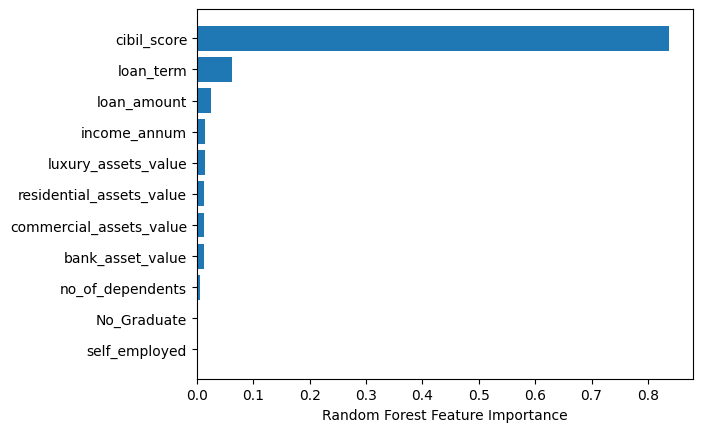

In [17]:
x =  df.drop(['loan_status'],axis=1)

plt.barh(range(len(sorted_idx)),feautures[sorted_idx])
plt.yticks(range(len(sorted_idx)), x.columns[sorted_idx])
plt.xlabel("Random Forest Feature Importance")
plt.show()

In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   no_of_dependents          4269 non-null   int64
 1   self_employed             4269 non-null   int64
 2   income_annum              4269 non-null   int64
 3   loan_amount               4269 non-null   int64
 4   loan_term                 4269 non-null   int64
 5   cibil_score               4269 non-null   int64
 6   residential_assets_value  4269 non-null   int64
 7   commercial_assets_value   4269 non-null   int64
 8   luxury_assets_value       4269 non-null   int64
 9   bank_asset_value          4269 non-null   int64
 10  loan_status               4269 non-null   int64
 11  No_Graduate               4269 non-null   int64
dtypes: int64(12)
memory usage: 400.3 KB


In [28]:
import pandas as pd

def create_prediction_dataframe():
    """
    Prompts the user to input integer values for the prediction DataFrame and returns a DataFrame.
    """
    # Input prompts for each column
    print("Please provide the following details (all inputs should be integers):")
    
    try:
        no_of_dependents = int(input("Number of Dependents (e.g., 0, 1, 2): "))
        self_employed = int(input("Self-Employed (1 for Yes, 0 for No): "))
        income_annum = int(input("Annual Income (in INR, e.g., 500000): "))
        loan_amount = int(input("Loan Amount (e.g., 250000): "))
        loan_term = int(input("Loan Term (in months, e.g., 60): "))
        cibil_score = int(input("CIBIL Score (e.g., 750): "))
        residential_assets_value = int(input("Residential Assets Value (e.g., 200000): "))
        commercial_assets_value = int(input("Commercial Assets Value (e.g., 100000): "))
        luxury_assets_value = int(input("Luxury Assets Value (e.g., 50000): "))
        bank_asset_value = int(input("Bank Asset Value (e.g., 300000): "))
        no_graduate = int(input("Not Graduate (1 for No Graduate, 0 for Graduate): "))
        
        # Creating the DataFrame
        data = {
            'no_of_dependents': [no_of_dependents],
            'self_employed': [self_employed],
            'income_annum': [income_annum],
            'loan_amount': [loan_amount],
            'loan_term': [loan_term],
            'cibil_score': [cibil_score],
            'residential_assets_value': [residential_assets_value],
            'commercial_assets_value': [commercial_assets_value],
            'luxury_assets_value': [luxury_assets_value],
            'bank_asset_value': [bank_asset_value],
            'No_Graduate': [no_graduate],
        }
        
        df = pd.DataFrame(data)
        print("\nDataFrame created successfully:\n")
        print(df)
        return df
    
    except ValueError:
        print("\nError: Please ensure all inputs are integers.")
        return None

# Example usage
input_df = create_prediction_dataframe()




Please provide the following details (all inputs should be integers):

DataFrame created successfully:

   no_of_dependents  self_employed  income_annum  loan_amount  loan_term  \
0                 2              1        130000       400000         40   

   cibil_score  residential_assets_value  commercial_assets_value  \
0          700                    100000                   500000   

   luxury_assets_value  bank_asset_value  No_Graduate  
0                25000            400000            0  


In [26]:
input_df = scaler_s.transform(input_df)

c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\base.py:444: UserWarning: X has feature names, but StandardScaler was fitted without feature names
  f"X has feature names, but {self.__class__.__name__} was fitted without"


In [29]:
prediction = model.predict(input_df)
print("Prediction result: Approved" if prediction[0] == 1 else "Prediction result: Rejected" )

Prediction result: Approved


c:\Users\v.rajkumar\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\base.py:444: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  f"X has feature names, but {self.__class__.__name__} was fitted without"
